# ML_Chapter 1 and 2

## Chapter 1

1. Why  Machine learning - insights + Predections
2. Types of machine  learning
   - Supervised learning
      - X and Y pressent in the data
   - Unsupervised learning
      - Only  X present  [Grouping,Clustring]
   - Reinforcement learning
      - Like training a Kid, with reward system. 
   - Self supervised learning
   - Semi supervised learning
3. ML  Pipeline
   1. Bussinesss understanding
   2. Data collection
   3. Data understanding
   4. Data preperation
   5. Model  Building
   6. Model Training
   7. Model Testing
   8. Model Evaluation
   9. Model  Deployment
   10. CI/CD

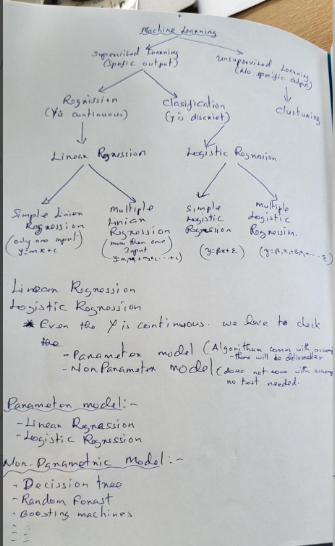

## Chapter 2 - Linear Regression

### Theory

Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value by finding the relationship between one or more independent variables (features) and a dependent variable (target).

**y=mx+c**

Where:
 - y = predicted value
 - x = input feature
 - m = slope (coefficient)
 - c = intercept

For multiple features:

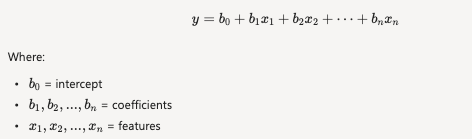

  - Counting → **Discrete**
  - Measuring → **Continuous**

For your stock screening example:

  - Relative Volume = Continuous
  - Stock Price = Continuous
  - Number of Trades = Discrete
  - Buy/Sell Signal = Discrete (Classification Target)


Parmetric models main deliverables are **Coefficient and intercept**  from the training  data.
 - When Y  is continuous we will be knoking the door of Regression algorithums. (Linear, logistic regression)  

**Real-World Applications**
 - House price prediction
 - Stock price forecasting
 - Sales forecasting
 - Salary prediction
 - Demand forecasting
 - Currency exchange rate prediction
 - MAP/LPP price trend analysis

**Advantages**
 - ✅ Simple and easy to understand
 - ✅ Fast training
 - ✅ Works well on linearly related data
 - ✅ Highly interpretable

**Limitations**
 - ❌ Cannot capture complex non-linear relationships
 - ❌ Sensitive to outliers
 - ❌ Performance decreases when assumptions are violated

#### Assumptions

#### Example 1

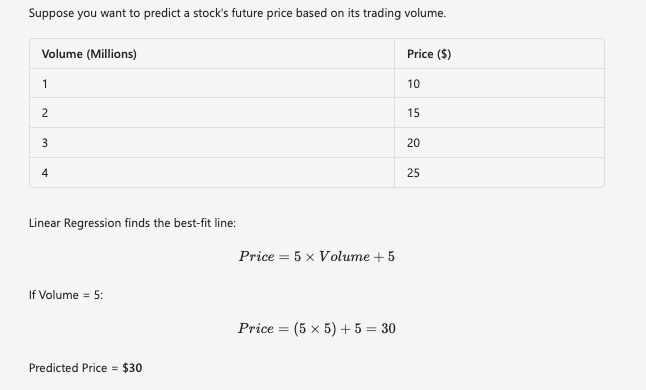

In [16]:
x_bar = (1+2+3+4)/4 
y_bar =(10+15+20+25)/4
print(x_bar,y_bar)
#m = E(yi-y_bar)/(xi-x_bar)


2.5 17.5
-11.0


<div>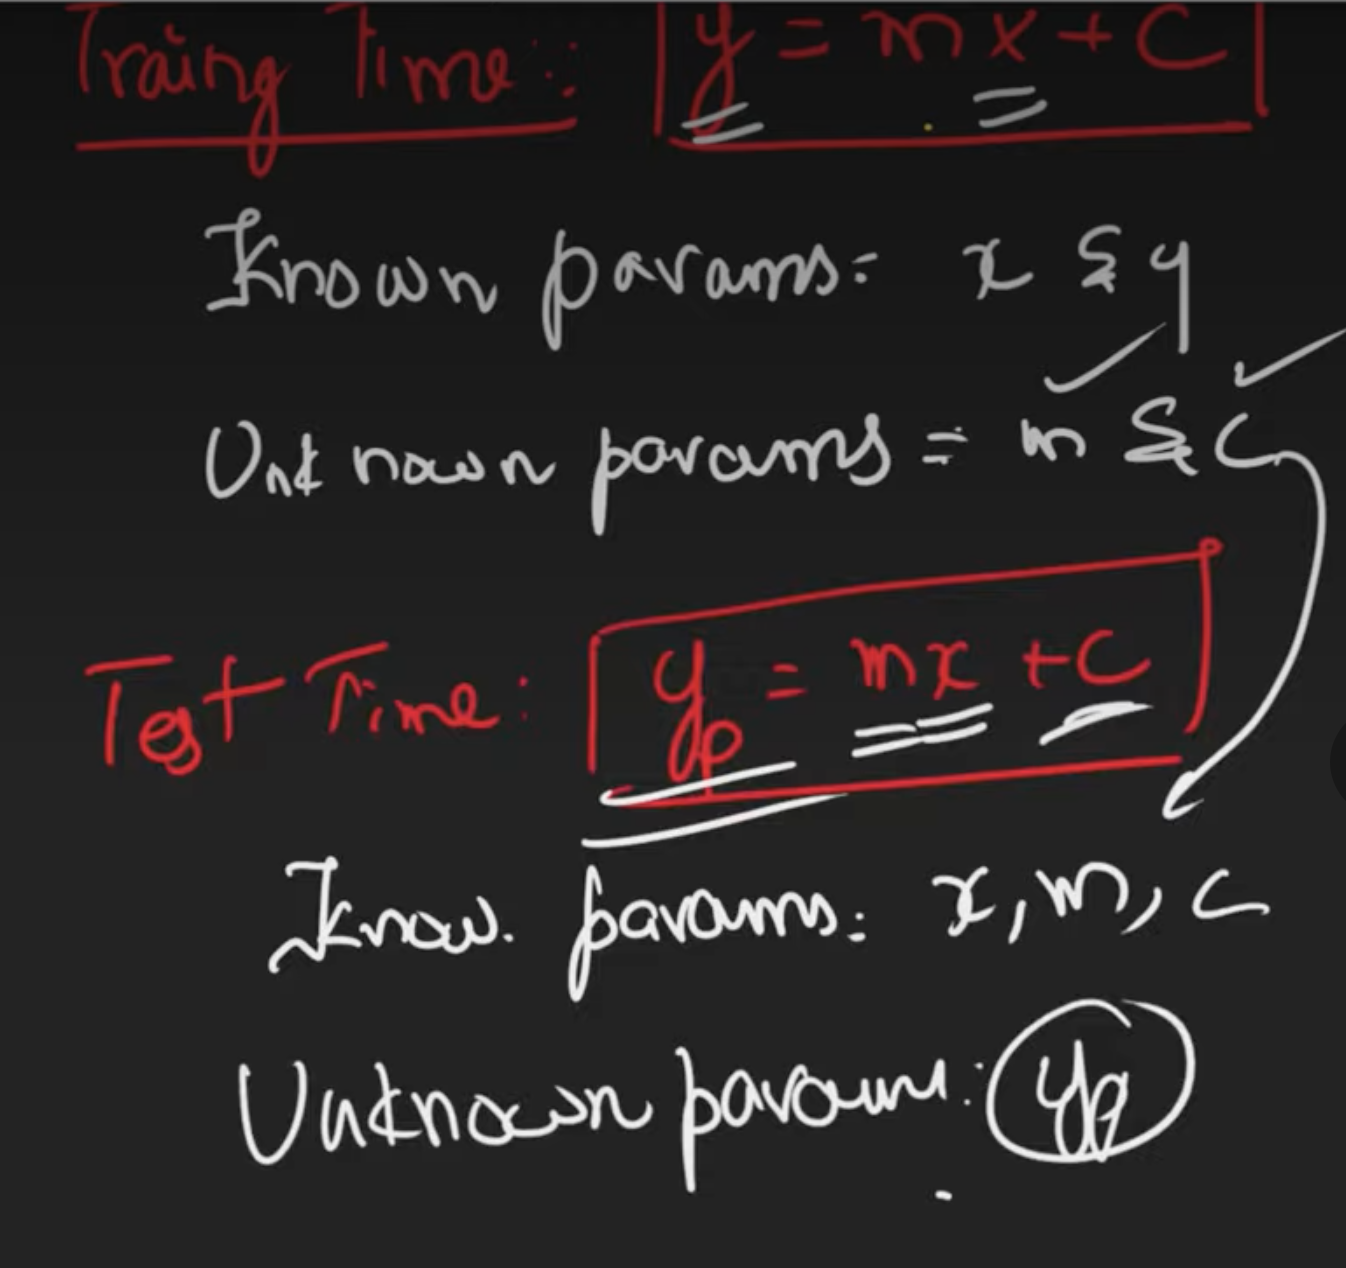 </div>

<div>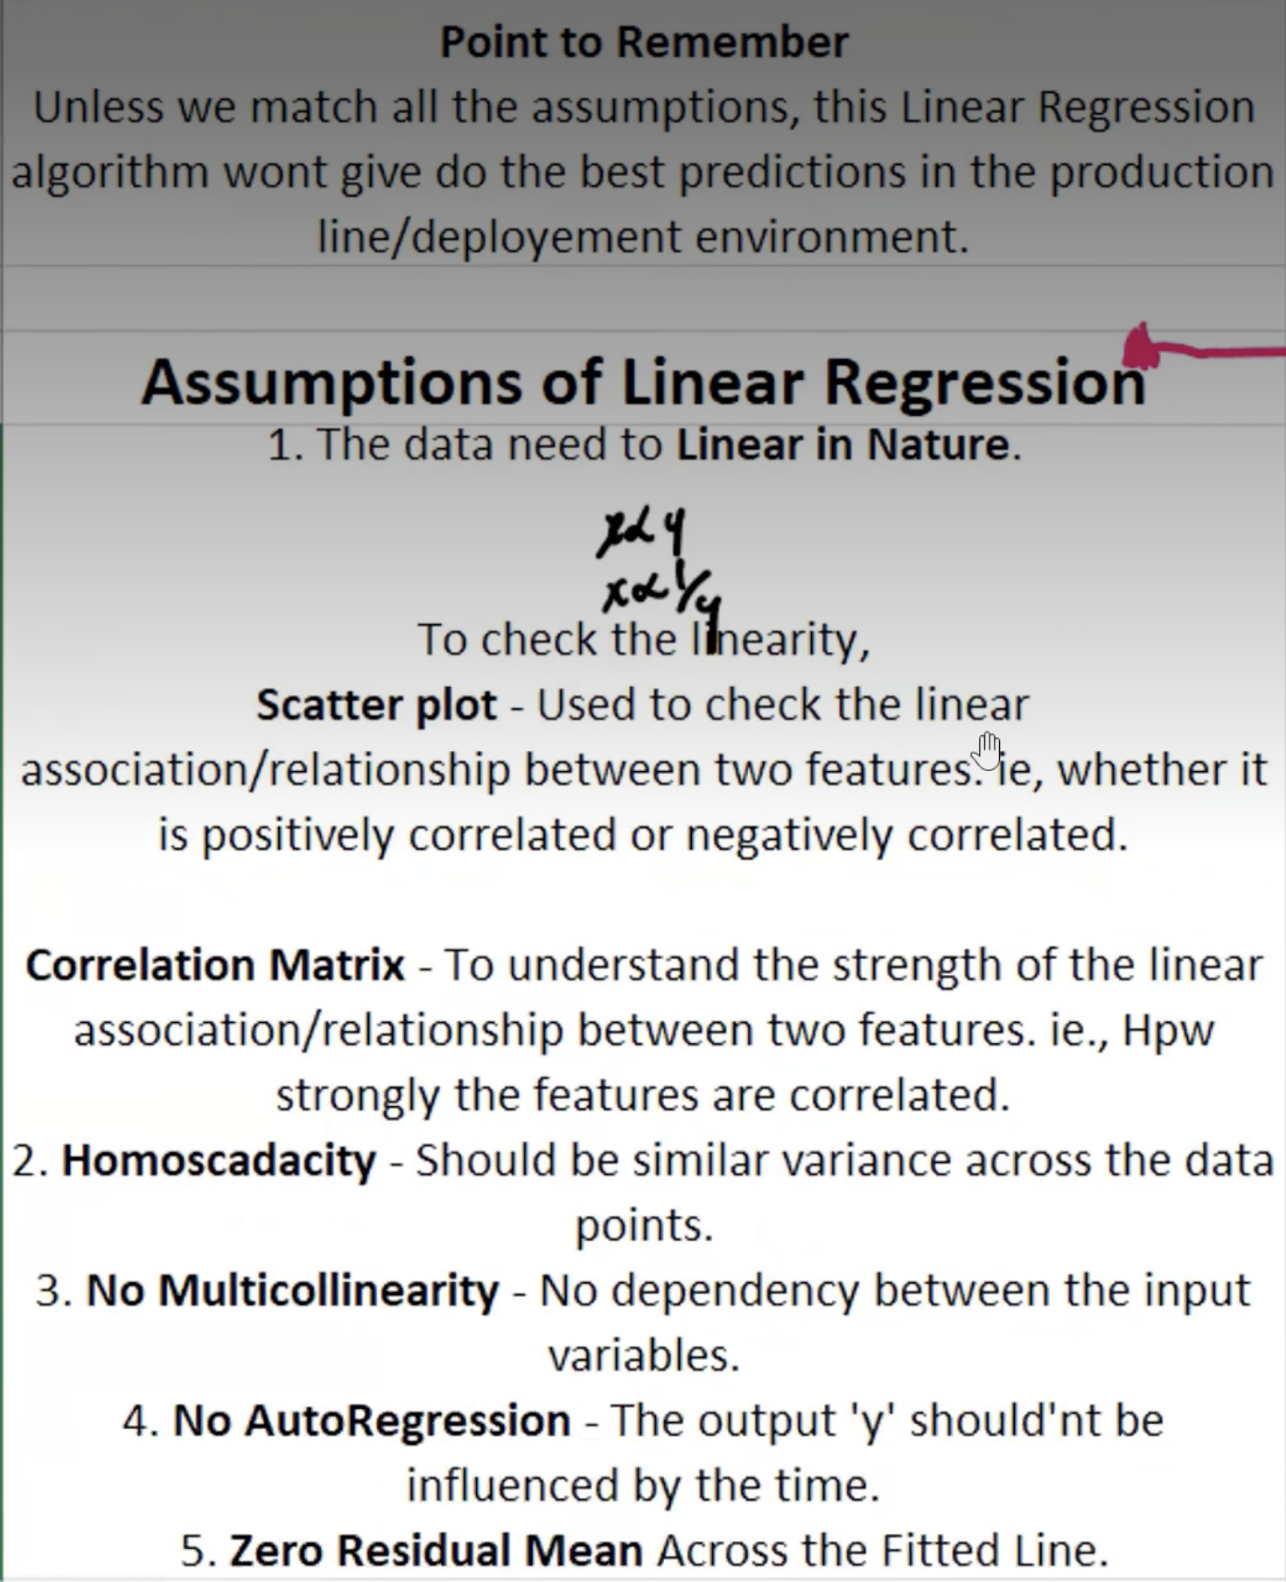 </div>

In [4]:
from  sklearn.linear_model import LinearRegression
import pandas as  pd
import warnings
warnings.filterwarnings("ignore")

#  Sample data
x=pd.DataFrame({'Volume':[1,2,3,4]})
y = [10,15,20,25]

#  Train model
model = LinearRegression()
model.fit(x,y)

# Prediction
predicted_price = model.predict([[5]])
print(predicted_price)

[30.]


In [6]:
#  Evalution metrics
#==============================================
# R² Score: Measures goodness of fit (0 to 1)
# MAE: Mean Absolute Error
# MSE: Mean Squared Error
# RMSE: Root Mean Squared Error
#==============================================

from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

y_true = [10, 15, 20, 25]
y_pred = [11, 14, 19, 26]

print("R2:", r2_score(y_true, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_true, y_pred)))

R2: 0.968
RMSE: 1.0


#### Example 2

##### 2.1 Import necessary libraries

In [97]:
import  pandas as pd
from matplotlib import pyplot as plt
import seaborn  as sns
from sklearn.linear_model import LinearRegression
from pickle import dump,load

##### 2.2 Import Dataaset

In [18]:
cars_data = pd.read_csv("cars.csv")
cars_data

,HP,MPG,VOL,SP,WT
0,49,53.700681,89,104.185353,28.762059
1,55,50.013401,92,105.461264,30.466833
2,55,50.013401,92,105.461264,30.193597
3,70,45.696322,92,113.461264,30.632114
4,53,50.504232,92,104.461264,29.889149
...,...,...,...,...,...
76,322,36.900000,50,169.598513,16.132947
77,238,19.197888,115,150.576579,37.923113
78,263,34.000000,50,151.598513,15.769625
79,295,19.833733,119,167.944460,39.423099


##### 2.3 Data  understanding

In [20]:
cars_data.shape

(81, 5)

In [21]:
cars_data.dtypes

HP       int64
MPG    float64
VOL      int64
SP     float64
WT     float64
dtype: object

In [22]:
cars_data.isna().sum()

HP     0
MPG    0
VOL    0
SP     0
WT     0
dtype: int64

In [24]:
cars_data.describe()

,HP,MPG,VOL,SP,WT
count,81.000000,81.000000,81.000000,81.000000,81.000000
mean,117.469136,34.422076,98.765432,121.540272,32.412577
std,57.113502,9.131445,22.301497,14.181432,7.492813
min,49.000000,12.101263,50.000000,99.564907,15.712859
25%,84.000000,27.856252,89.000000,113.829145,29.591768
50%,100.000000,35.152727,101.000000,118.208698,32.734518
75%,140.000000,39.531633,113.000000,126.404312,37.392524
max,322.000000,53.700681,160.000000,169.598513,52.997752


###### 2.2.1 Assumption test

###### 2.2.1.1 Linearity Test

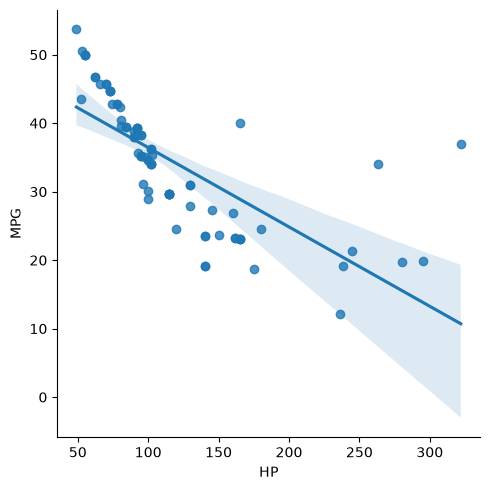

In [52]:
sns.lmplot(cars_data,x="HP",y="MPG")

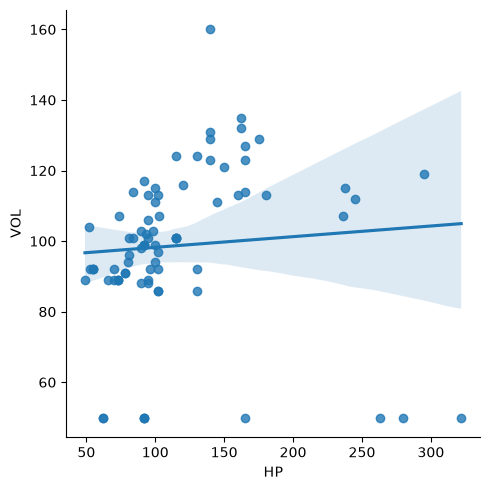

In [33]:
sns.lmplot(cars_data,x="HP",y="VOL")

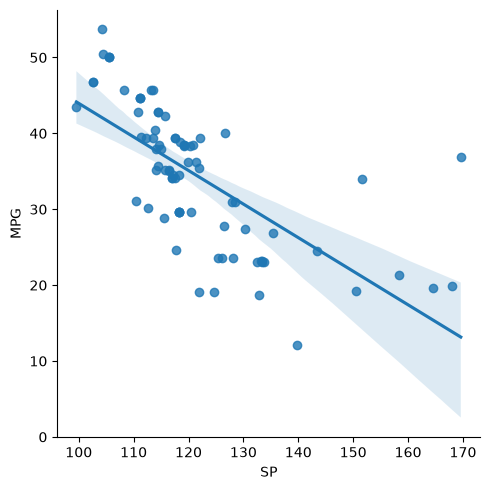

In [37]:
sns.lmplot(cars_data,x="SP",y="MPG")

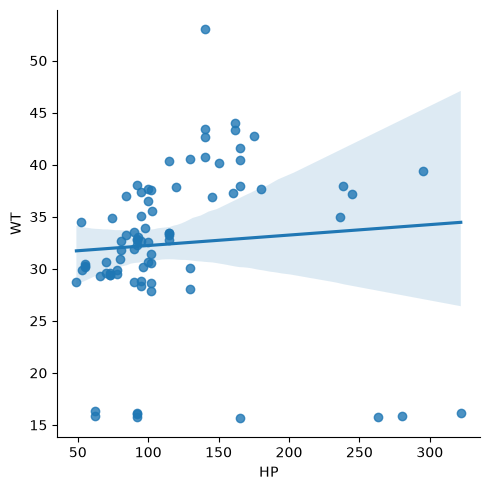

In [36]:
sns.lmplot(cars_data,x="HP",y="WT")

**Test 1 failed. All points are not falling  on the leaniar line.** We can also use scater plot for this test too.

###### 2.2.1.2 Normality Test

(array([15., 35.,  9.,  6.,  9.,  0.,  2.,  2.,  1.,  2.]),
 array([ 49. ,  76.3, 103.6, 130.9, 158.2, 185.5, 212.8, 240.1, 267.4,
        294.7, 322. ]),
 <BarContainer object of 10 artists>)

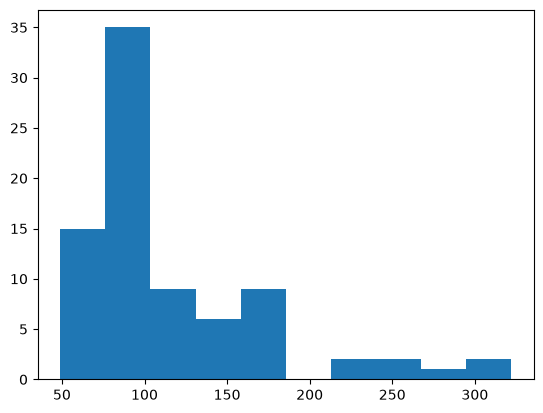

In [39]:
plt.hist(cars_data["HP"])

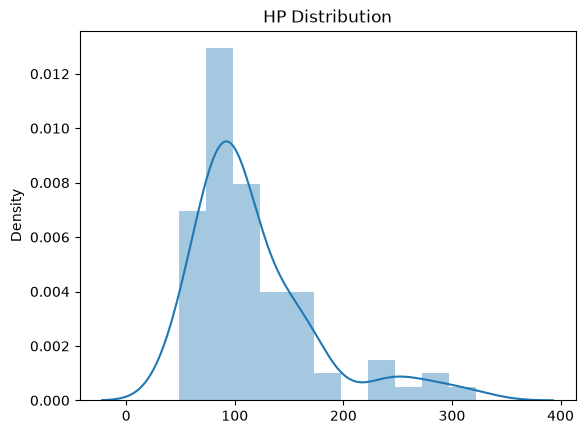

In [43]:
sns.distplot(x=cars_data["HP"])
plt.title("HP Distribution")
plt.show()

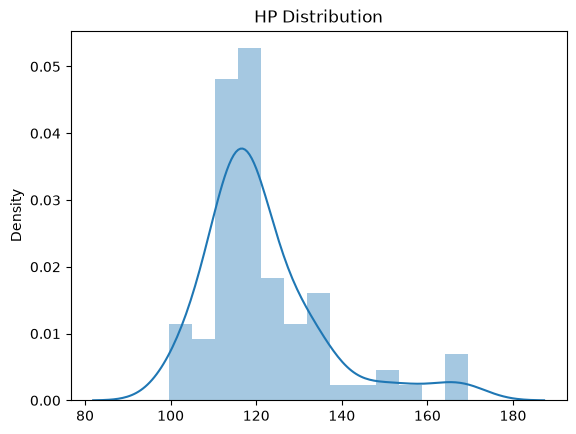

In [44]:
sns.distplot(x=cars_data["SP"])
plt.title("HP Distribution")
plt.show()

**Normality Test 2 failed. We did not get a cemetric graph.**

###### 2.2.1.3 Corlation metrix

In [47]:
corr_matrix = cars_data.corr()
corr_matrix

,HP,MPG,VOL,SP,WT
HP,1.000000,-0.725038,0.077459,0.973848,0.076513
MPG,-0.725038,1.000000,-0.529057,-0.687125,-0.526759
VOL,0.077459,-0.529057,1.000000,0.102170,0.999203
SP,0.973848,-0.687125,0.102170,1.000000,0.102439
WT,0.076513,-0.526759,0.999203,0.102439,1.000000


In [ ]:
HP and b SP are high correlation.This is not good.

<Axes: >

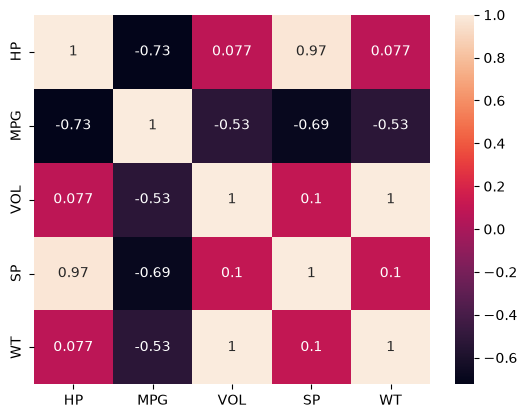

In [50]:
sns.heatmap(data=corr_matrix,annot=True)

SP or HP  one of the 2 is enough in our prediction  because those reprecent the same behaviour.
-  There is Multicollineraity in  this data.

###### 2.2.1.4 Linearity Test

AutoRegression Passed. No date  or time sensitive data in  the input.

###### 2.2.1.5 Homascadacity test

##### 2.4 Data  Preperation

In [ ]:
All data are in numeric so  nothing to prepare.b

##### 2.5 Model Building

In [84]:
linear_model = LinearRegression()
X = cars_data[["HP","VOL","SP","WT"]]
y = cars_data["MPG"]

##### 2.6 Model Training

In [85]:
linear_model.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.21,-0.34, 0.4 , 0.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['HP','VOL','SP','WT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,30.68
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [86]:
linear_model.intercept_

np.float64(30.67733585215172)

In [87]:
linear_model.coef_ # 4 input

array([-0.20544372, -0.33605084,  0.39562692,  0.40057409])

##### 2.7 Model Testing

In [88]:
y_pred = linear_model.predict(X)
y_pred

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

##### 2.8 Model Evaluation

In [89]:
error  = y - y_pred
error
#hier  we can perform the Homoscedasiticty tesst

0     10.258747
1      7.624608
2      7.734060
3      3.157963
4      8.331584
        ...    
76    15.617904
77     1.298838
78     7.863547
79     7.517122
80    -3.458218
Name: MPG, Length: 81, dtype: float64

###### 2.2.1.5 Homoscedasticity test

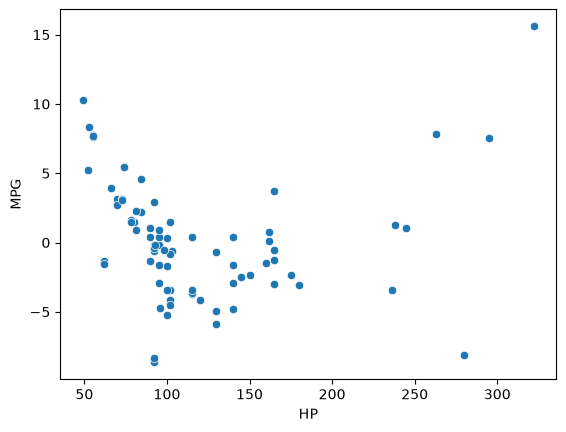

In [90]:
sns.scatterplot(data=cars_data,x = "HP",y = error)
plt.show()

**There   is  no similar error from 0 to  up or down. So this test is also failed.**

###### 2.2.1.6 Zero Residual Mean Test

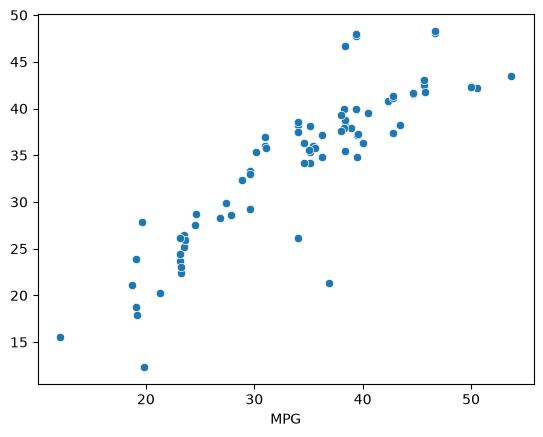

In [93]:
sns.scatterplot(x=cars_data["MPG"],y = y_pred)
plt.show()

**Zero Residual Mean Test also failed.**

##### 2.9 Model Deployment

In [96]:
dump(obj=linear_model,file=open(file="Linear_intelligence_file.pkl",mode="wb"))

In [98]:
linear_intel_pkl = load(file=open(file="Linear_intelligence_file.pkl",mode="rb"))
linear_intel_pkl 

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[-0.21,-0.34, 0.4 , 0.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['HP','VOL','SP','WT']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,30.68
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [100]:
linear_intel_pkl.predict(X)

array([43.44193477, 42.38879289, 42.27934147, 42.53835981, 42.17264802,
       43.02061916, 42.32536062, 48.07621852, 48.28120247, 40.79122814,
       41.52153227, 47.80956747, 39.95980269, 41.52757889, 41.76632332,
       41.6181448 , 41.15094046, 47.98605515, 41.30861046, 37.87127922,
       38.57706414, 37.35199705, 37.89770285, 39.5625144 , 39.93380662,
       46.73870908, 35.48165898, 38.78152504, 38.24861192, 36.00285298,
       34.84603989, 37.21630246, 37.13919796, 34.82541399, 37.22361389,
       37.53950097, 39.27144845, 38.24219888, 38.54286458, 35.9391722 ,
       34.2129755 , 35.36313259, 37.50473376, 38.07998482, 35.79651664,
       36.2613377 , 34.21826465, 35.59393404, 36.91805291, 33.31108154,
       33.21313413, 33.3023649 , 29.19864884, 27.52358579, 28.3207133 ,
       28.56722621, 35.81583602, 33.02108459, 35.37334971, 32.29909503,
       29.87685849, 28.76093817, 25.14188416, 26.47040896, 25.97651933,
       36.35652478, 26.0975912 , 23.6416178 , 24.39887199, 20.21

## The End